# 04 — Fairness Analysis
**Project:** FairCredit AI

## Goal
Evaluate whether the selected credit-default model behaves differently across demographic groups.

This notebook:
- loads and prepares the same dataset,
- creates a stratified train/test split,
- trains Logistic Regression on the training data,
- evaluates the model on the held-out test data,
- compares default prediction rates, recall, and false positive rates across `SEX` and `AGE` groups.

**Important:** These are descriptive fairness checks, not proof that a model is fair or unfair. Differences may reflect data, model limitations, or group sample sizes. Do not use these results alone to make real credit decisions.

## 1. Import libraries
We use pandas for data handling, matplotlib for plots, and scikit-learn for splitting, preprocessing, modeling, and metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

RANDOM_STATE = 42

## 2. Load the dataset
This file path assumes the notebook is saved in the `notebooks/` folder and the Excel file is saved in `data/`.

In [2]:
df = pd.read_excel("../data/default of credit card clients.xls", header=1)

# Rename the target column to a short name
df = df.rename(columns={"default payment next month": "DEFAULT"})

print("Dataset shape:", df.shape)
display(df.head())

/tmp/ipykernel_91565/262379562.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel("../data/default of credit card clients.xls", header=1)


Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Check the target distribution
Check the class balance before training. This dataset has more non-defaulters than defaulters, so accuracy alone can be misleading.

In [3]:
print("Target counts:")
display(df["DEFAULT"].value_counts().sort_index())

print("\nTarget percentages:")
display((df["DEFAULT"].value_counts(normalize=True).sort_index() * 100).round(2))

Target counts:


DEFAULT
0    23364
1     6636
Name: count, dtype: int64


Target percentages:


DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64

## 4. Prepare features and target
`ID` is an identifier, so it is excluded from model features. `SEX` and `AGE` are retained here for fairness-group analysis; the model feature setup below uses the same feature set as the training notebook.

In [4]:
X = df.drop(columns=["DEFAULT", "ID"])
y = df["DEFAULT"].astype(int)

categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]

numerical_cols = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

# Keep the same rows aligned for group analysis
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 24000
Testing records: 6000


## 5. Train a baseline model
We use Logistic Regression because it had the highest ROC-AUC in the earlier model comparison. The preprocessing is fitted only on training data through the pipeline.

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", StandardScaler(), numerical_cols)
    ]
)

fairness_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

fairness_model.fit(X_train, y_train)

y_pred = fairness_model.predict(X_test)
y_prob = fairness_model.predict_proba(X_test)[:, 1]

print("Baseline test metrics")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Baseline test metrics
Accuracy: 0.817
Precision: 0.661
Recall: 0.352
F1-score: 0.459
ROC-AUC: 0.758


## 6. Create one aligned test-results table
This table contains the true outcome, predicted outcome, and protected/group attributes for each test record. We use `X_test.index` to keep the group attributes aligned with predictions.

In [6]:
test_results = X_test[["SEX", "AGE"]].copy()
test_results["actual"] = y_test
test_results["predicted"] = y_pred
test_results["default_probability"] = y_prob

print("Test result rows:", len(test_results))
display(test_results.head())

Test result rows: 6000


,SEX,AGE,actual,predicted,default_probability
6907,1,46,0,0,0.155765
24575,1,31,0,0,0.196578
26766,1,25,0,0,0.140744
2156,2,25,1,0,0.096642
3179,2,27,0,0,0.069015


## 7. Define group fairness metrics
For each group we calculate:
- **Prediction rate:** share predicted as default.
- **Recall / true positive rate:** share of actual defaulters correctly identified.
- **False positive rate:** share of actual non-defaulters incorrectly predicted as defaulters.
- **Support:** number of records in the group.

Rates are returned as `NaN` when the denominator is zero. Small groups can make estimates unstable.

In [7]:
def calculate_group_metrics(group):
    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()

    actual_default = actual == 1
    actual_no_default = actual == 0
    predicted_default = predicted == 1

    prediction_rate = predicted_default.mean() if len(group) > 0 else np.nan

    recall = (
        (predicted_default & actual_default).sum() / actual_default.sum()
        if actual_default.sum() > 0 else np.nan
    )

    false_positive_rate = (
        (predicted_default & actual_no_default).sum() / actual_no_default.sum()
        if actual_no_default.sum() > 0 else np.nan
    )

    return pd.Series({
        "Records": len(group),
        "Actual default rate": actual.mean() if len(group) > 0 else np.nan,
        "Predicted default rate": prediction_rate,
        "Recall": recall,
        "False positive rate": false_positive_rate
    })

## 8. Fairness analysis by SEX
The dataset codes `SEX` as 1 and 2. We report the original codes without assuming labels beyond the dataset documentation. Compare rates and sample sizes; differences are signals to investigate, not automatic proof of unfairness.

In [8]:
sex_metrics = test_results.groupby("SEX").apply(
    calculate_group_metrics, include_groups=False
).reset_index()

display(sex_metrics.round(3))

,SEX,Records,Actual default rate,Predicted default rate,Recall,False positive rate
0,1,2402.0,0.234,0.127,0.349,0.059
1,2,3598.0,0.213,0.112,0.354,0.046


### Plot: predicted default rate by SEX
This plot compares the share of test records predicted as defaulters in each group.

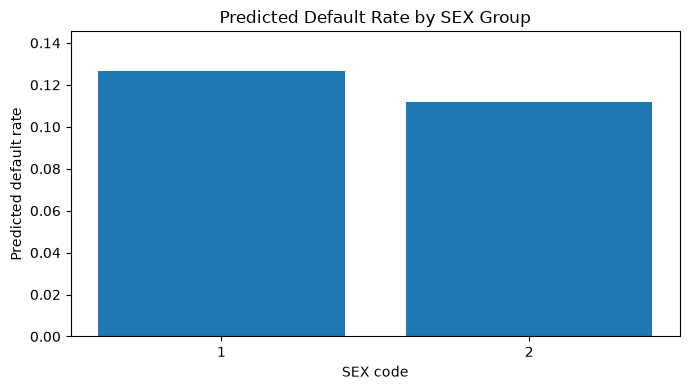

In [9]:
plt.figure(figsize=(7, 4))
plt.bar(sex_metrics["SEX"].astype(str), sex_metrics["Predicted default rate"])
plt.xlabel("SEX code")
plt.ylabel("Predicted default rate")
plt.title("Predicted Default Rate by SEX Group")
plt.ylim(0, max(0.05, sex_metrics["Predicted default rate"].max() * 1.15))
plt.tight_layout()
plt.show()

## 9. Fairness analysis by AGE group
We create broad age bands for easier interpretation. The age bands are descriptive choices, not legal definitions of protected classes.

In [10]:
age_bins = [0, 29, 39, 49, 59, np.inf]
age_labels = ["29 or younger", "30–39", "40–49", "50–59", "60+"]

test_results["AGE_GROUP"] = pd.cut(
    test_results["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

age_metrics = test_results.groupby("AGE_GROUP", observed=False).apply(
    calculate_group_metrics, include_groups=False
).reset_index()

display(age_metrics.round(3))

,AGE_GROUP,Records,Actual default rate,Predicted default rate,Recall,False positive rate
0,29 or younger,1912.0,0.223,0.134,0.396,0.059
1,30–39,2198.0,0.206,0.099,0.316,0.043
2,40–49,1341.0,0.233,0.118,0.337,0.052
3,50–59,473.0,0.237,0.131,0.366,0.058
4,60+,76.0,0.303,0.158,0.391,0.057


### Plot: recall by AGE group
Recall shows the fraction of actual defaulters detected within each age group. Check `Records` and actual default counts before interpreting differences.

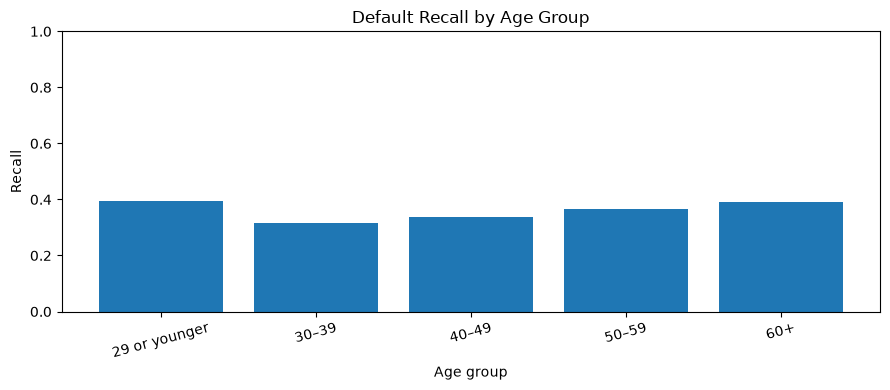

In [11]:
plt.figure(figsize=(9, 4))
plt.bar(age_metrics["AGE_GROUP"].astype(str), age_metrics["Recall"])
plt.xlabel("Age group")
plt.ylabel("Recall")
plt.title("Default Recall by Age Group")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Check group sizes and actual default counts
Group metrics are easier to interpret when their denominators are visible. This table reports the number of actual defaulters and non-defaulters in each age band.

In [12]:
age_support = test_results.groupby("AGE_GROUP", observed=False).agg(
    Records=("actual", "size"),
    Actual_defaulters=("actual", "sum"),
    Actual_non_defaulters=("actual", lambda s: (s == 0).sum())
).reset_index()

display(age_support)

,AGE_GROUP,Records,Actual_defaulters,Actual_non_defaulters
0,29 or younger,1912,427,1485
1,30–39,2198,453,1745
2,40–49,1341,312,1029
3,50–59,473,112,361
4,60+,76,23,53


## 11. Add 95% confidence intervals to group metrics

A confidence interval shows uncertainty around an estimated rate. Here we use the **Wilson 95% interval** for proportions, which behaves better than a simple normal interval when group counts are small.

- Prediction-rate intervals use all records in a group.
- Recall intervals use only actual defaulters in that group.
- False-positive-rate intervals use only actual non-defaulters in that group.

These intervals are approximate uncertainty summaries for this held-out test sample. Overlapping intervals do not prove that groups are equal, and non-overlap is not by itself a complete fairness test.

SEX group metrics with 95% Wilson confidence intervals


,SEX,Records,Predicted default rate,Predicted rate 95% CI lower,Predicted rate 95% CI upper,Recall,Recall 95% CI lower,Recall 95% CI upper,False positive rate,FPR 95% CI lower,FPR 95% CI upper
0,1,2402.0,0.127,0.114,0.140,0.349,0.311,0.390,0.059,0.049,0.070
1,2,3598.0,0.112,0.102,0.122,0.354,0.321,0.388,0.046,0.039,0.055


AGE group metrics with 95% Wilson confidence intervals


,AGE_GROUP,Records,Predicted default rate,Predicted rate 95% CI lower,Predicted rate 95% CI upper,Recall,Recall 95% CI lower,Recall 95% CI upper,False positive rate,FPR 95% CI lower,FPR 95% CI upper
0,29 or younger,1912.0,0.134,0.119,0.150,0.396,0.351,0.443,0.059,0.048,0.072
1,30–39,2198.0,0.099,0.087,0.112,0.316,0.275,0.360,0.043,0.034,0.054
2,40–49,1341.0,0.118,0.102,0.136,0.337,0.286,0.391,0.052,0.040,0.067
3,50–59,473.0,0.131,0.104,0.164,0.366,0.283,0.458,0.058,0.038,0.087
4,60+,76.0,0.158,0.093,0.256,0.391,0.222,0.592,0.057,0.019,0.154


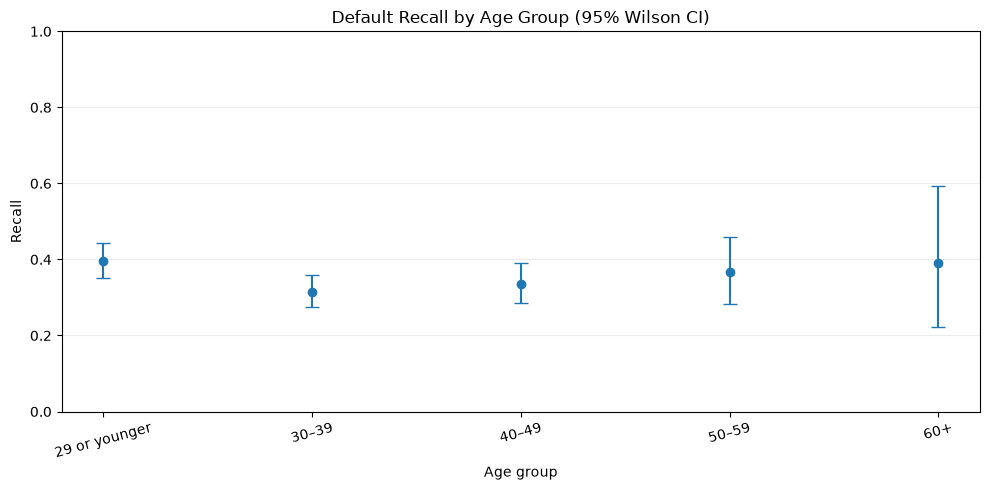

In [13]:
from math import sqrt

def wilson_interval(successes, total, z=1.96):
    """Return a 95% Wilson confidence interval for a binomial proportion."""
    if total == 0:
        return (np.nan, np.nan)

    p = successes / total
    denominator = 1 + (z**2 / total)
    center = (p + z**2 / (2 * total)) / denominator
    margin = (
        z
        * sqrt((p * (1 - p) / total) + (z**2 / (4 * total**2)))
        / denominator
    )
    return (max(0, center - margin), min(1, center + margin))


def group_metrics_with_ci(group):
    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()

    n = len(group)
    predicted_default_count = int((predicted == 1).sum())

    actual_default = actual == 1
    actual_non_default = actual == 0
    true_positive_count = int(((predicted == 1) & actual_default).sum())
    false_positive_count = int(((predicted == 1) & actual_non_default).sum())

    pred_low, pred_high = wilson_interval(predicted_default_count, n)
    recall_low, recall_high = wilson_interval(
        true_positive_count, int(actual_default.sum())
    )
    fpr_low, fpr_high = wilson_interval(
        false_positive_count, int(actual_non_default.sum())
    )

    return pd.Series({
        "Records": n,
        "Predicted default rate": predicted_default_count / n if n else np.nan,
        "Predicted rate 95% CI lower": pred_low,
        "Predicted rate 95% CI upper": pred_high,
        "Recall": (
            true_positive_count / int(actual_default.sum())
            if actual_default.sum() else np.nan
        ),
        "Recall 95% CI lower": recall_low,
        "Recall 95% CI upper": recall_high,
        "False positive rate": (
            false_positive_count / int(actual_non_default.sum())
            if actual_non_default.sum() else np.nan
        ),
        "FPR 95% CI lower": fpr_low,
        "FPR 95% CI upper": fpr_high,
    })


# Confidence intervals by SEX
sex_metrics_ci = test_results.groupby("SEX").apply(
    group_metrics_with_ci, include_groups=False
).reset_index()

print("SEX group metrics with 95% Wilson confidence intervals")
display(sex_metrics_ci.round(3))

# Confidence intervals by AGE group
age_metrics_ci = test_results.groupby("AGE_GROUP", observed=False).apply(
    group_metrics_with_ci, include_groups=False
).reset_index()

print("AGE group metrics with 95% Wilson confidence intervals")
display(age_metrics_ci.round(3))

# Plot recall with 95% confidence intervals by age group
plot_age = age_metrics_ci.dropna(subset=["Recall"]).copy()
yerr_lower = plot_age["Recall"] - plot_age["Recall 95% CI lower"]
yerr_upper = plot_age["Recall 95% CI upper"] - plot_age["Recall"]

plt.figure(figsize=(10, 5))
plt.errorbar(
    plot_age["AGE_GROUP"].astype(str),
    plot_age["Recall"],
    yerr=[yerr_lower, yerr_upper],
    fmt="o",
    capsize=5
)
plt.xlabel("Age group")
plt.ylabel("Recall")
plt.title("Default Recall by Age Group (95% Wilson CI)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Summary and limitations
Use the newly computed tables and plots above to write a short, evidence-based summary. Re-run the notebook before reporting numbers.

- Which SEX group has the higher predicted default rate?<br>
    SEX group 1: 12.66%, compared with 11.17% for group 2.
    
- Which age group has the highest recall?<br>
    29 or younger: 39.58%
    
- Are any groups small enough that their rates may be unstable?<br>
    Yes. The 60+ group has just 76 test records, including 23 actual defaulters.
    
- Do groups have different false positive rates?<br>
    Yes. By SEX, 5.87% versus 4.63%. By age, rates range from 4.30% to 5.86%.
    